Caspase × Mito × Mito Viability — DBSCAN Clustering (per case)

EPS is auto-detected per dataset from the k-distance elbow (second-derivative peak).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator, rdFMCS
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import umap
import pubchempy as pcp

BASE     = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
RESULTS  = BASE + 'results/casepase_mito_comparisons/'
ENCODING = 'utf-8'

DATASETS = [
    ('Case 1: Casp+ Mito+ MitoViab+', 'case1_caspase_active_mito_active_viability_active.csv'),
    ('Case 2: Casp+ Mito+ MitoViab-', 'case2_caspase_active_mito_active_viability_inactive.csv'),
    ('Case 3: Casp+ Mito- MitoViab+', 'case3_caspase_active_mito_inactive_viability_active.csv'),
    ('Case 4: Casp+ Mito- MitoViab-', 'case4_caspase_active_mito_inactive_viability_inactive.csv'),
    ('Case 5: Casp- Mito+ MitoViab+', 'case5_caspase_inactive_mito_active_viability_active.csv'),
    ('Case 6: Casp- Mito+ MitoViab-', 'case6_caspase_inactive_mito_active_viability_inactive.csv'),
    ('Case 7: Casp- Mito- MitoViab+', 'case7_caspase_inactive_mito_inactive_viability_active.csv'),
    ('Case 8: Casp- Mito- MitoViab-', 'case8_caspase_inactive_mito_inactive_viability_inactive.csv'),
]

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# ── Fingerprint helpers ──────────────────────────────────────────────────────
def to_fp_matrix(mols):
    fps = [gen.GetFingerprint(m) for m in mols]
    mat = np.array([list(fp.ToBitString()) for fp in fps], dtype=np.float32)
    return fps, mat

# ── UMAP helper ──────────────────────────────────────────────────────────────
def plot_umap(fp_matrix, labels, title='UMAP', color_map=None, annotate=None):
    n = len(fp_matrix)
    reducer = umap.UMAP(n_neighbors=min(15, n - 1),
                        min_dist=0.3, metric='jaccard', random_state=42)
    emb = reducer.fit_transform(fp_matrix)
    unique = list(dict.fromkeys(labels))
    if color_map is None:
        color_map = {l: plt.cm.tab10(i % 10) for i, l in enumerate(unique)}
    fig, ax = plt.subplots(figsize=(9, 7))
    for lbl in unique:
        mask = np.array([l == lbl for l in labels])
        ax.scatter(emb[mask, 0], emb[mask, 1], c=[color_map[lbl]],
                   label=lbl, s=60, edgecolors='black', linewidths=0.4, alpha=0.85)
    if annotate is not None:
        for i, txt in enumerate(annotate):
            ax.annotate(str(txt), (emb[i, 0], emb[i, 1]),
                        textcoords='offset points', xytext=(4, 3), fontsize=6, color='#444')
    ax.legend(loc='upper left', fontsize=8.5, framealpha=0.9)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()
    return emb

# ── k-NN distance plot on 2D UMAP coords (Euclidean) ─────────────────────────
def knn_eps_plot(emb, min_samples, title):
    nbrs = NearestNeighbors(n_neighbors=min_samples + 1).fit(emb)
    distances, _ = nbrs.kneighbors(emb)
    sorted_d = np.sort(distances[:, -1])[::-1]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(sorted_d, 'b-', linewidth=1.5)
    ax.set_xlabel('Points sorted by decreasing distance')
    ax.set_ylabel(f'Euclidean dist to {min_samples}-th NN (UMAP space)')
    ax.set_title(f'{title}\nSelect eps at the knee  (min_samples={min_samples})')
    ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()
    print(f'  Min={sorted_d.min():.4f}  Median={np.median(sorted_d):.4f}  Max={sorted_d.max():.4f}')
    return sorted_d

# ── MCS core ─────────────────────────────────────────────────────────────────
def get_mcs_core(mols):
    if len(mols) < 2:
        return None
    mcs = rdFMCS.FindMCS(mols, ringMatchesRingOnly=True,
                         completeRingsOnly=True, timeout=10)
    if mcs and mcs.numAtoms >= 3:
        return Chem.MolFromSmarts(mcs.smartsString)
    return None

# ── Draw cluster reps + MCS core ─────────────────────────────────────────────
def draw_cluster_reps(dataset, title, mols_per_row=5, img_size=(280, 230),
                      max_per_cluster=12):
    from IPython.display import display
    reps, legs, highlights = [], [], []
    cl_name_map = {}
    print(f'Fetching PubChem names — {title}...')
    for cl in sorted(c for c in dataset['cluster'].unique() if c != -1):
        sub  = dataset[dataset['cluster'] == cl].reset_index(drop=True)
        fps  = sub['fp'].tolist()
        avg  = [sum(DataStructs.BulkTanimotoSimilarity(fp, fps)) for fp in fps]
        rep  = sub.loc[int(np.argmax(avg))]
        cid  = int(rep['PUBCHEM_CID'])
        try:
            c_   = pcp.Compound.from_cid(cid)
            syns = c_.synonyms or []
            short = [s for s in syns if len(s) <= 30 and s[0].isalpha()]
            name  = short[0] if short else (syns[0][:28] if syns else str(cid))
        except Exception:
            name = str(cid)
        cl_name_map[cl] = name
        cluster_mols = sub.head(max_per_cluster)['mol'].tolist()
        core = get_mcs_core(cluster_mols)
        if core is not None:
            reps.append(core); legs.append(f'C{cl} (n={len(sub)}) ★ Core ★'); highlights.append([])
        reps.append(rep['mol'])
        match = rep['mol'].GetSubstructMatch(core) if core is not None else []
        legs.append(f'C{cl} (n={len(sub)})\n{name} [CID {cid}]')
        highlights.append(list(match))
        print(f'  Cluster {cl:2d} (n={len(sub):4d})  {name}  [CID {cid}]')
    if not reps:
        print('  No clusters found — all compounds are structurally unique.')
        return cl_name_map
    img = Draw.MolsToGridImage(reps, molsPerRow=mols_per_row, subImgSize=img_size,
                               legends=legs, highlightAtomLists=highlights, returnPNG=False)
    display(img)
    return cl_name_map

# ── UMAP coloured by cluster ──────────────────────────────────────────────────
def umap_by_cluster(dataset, cl_name_map, title):
    fig, ax = plt.subplots(figsize=(10, 8))
    cmap  = plt.cm.tab10
    noise = dataset[dataset['cluster'] == -1]
    if len(noise):
        ax.scatter(noise['umap_x'], noise['umap_y'], c='#cccccc',
                   s=30, edgecolors='none', alpha=0.5,
                   label=f'unique / noise (n={len(noise)})')
    for cl in sorted(c for c in dataset['cluster'].unique() if c != -1):
        sub  = dataset[dataset['cluster'] == cl]
        name = cl_name_map.get(cl, f'Cluster {cl}')
        ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
                   s=60, edgecolors='black', linewidths=0.4, alpha=0.85,
                   label=f'C{cl}: {name} (n={len(sub)})')
    for _, row in dataset.iterrows():
        ax.annotate(str(int(row['PUBCHEM_CID'])), (row['umap_x'], row['umap_y']),
                    textcoords='offset points', xytext=(4, 3), fontsize=6, color='#444')
    ax.legend(loc='upper left', fontsize=7.5, framealpha=0.95, ncol=2)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()

print('Setup complete.')


Setup complete.


  Case 1: Casp+ Mito+ MitoViab+
Unique CIDs: 63
Valid molecules: 63


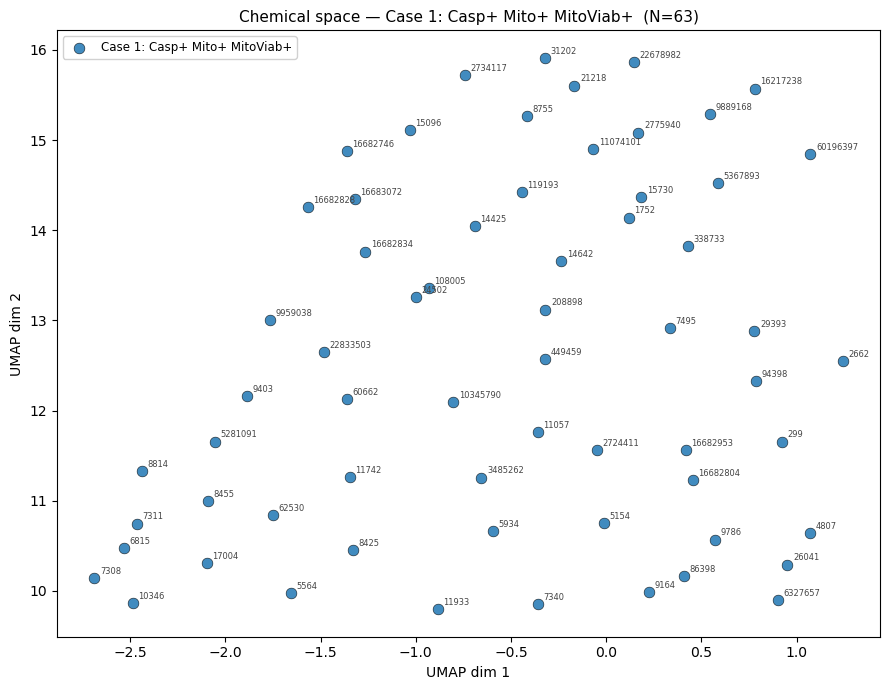

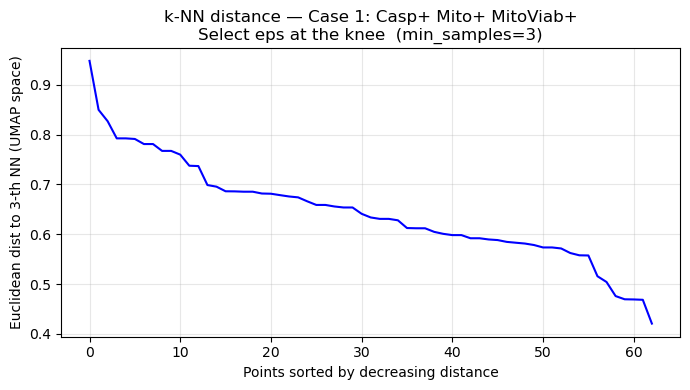

  Min=0.4209  Median=0.6338  Max=0.9479

DBSCAN (eps=0.45, min_samples=3)  →  6 clusters,  39 noise (61.9%)
           Count
Noise         39
Cluster 1      6
Cluster 0      4
Cluster 2      4
Cluster 5      4
Cluster 3      3
Cluster 4      3
Fetching PubChem names — Case 1: Casp+ Mito+ MitoViab+...
  Cluster  0 (n=   4)  p-Nonylphenol  [CID 1752]
  Cluster  1 (n=   6)  Di-tert-butyl-m-cresol  [CID 10346]
  Cluster  2 (n=   4)  Myristalkonium chloride  [CID 8755]
  Cluster  3 (n=   3)  o-Phthalaldehyde  [CID 4807]
  Cluster  4 (n=   3)  TRIPHENYLTIN FLUORIDE  [CID 9786]
  Cluster  5 (n=   4)  Caswell No. 866A  [CID 9889168]


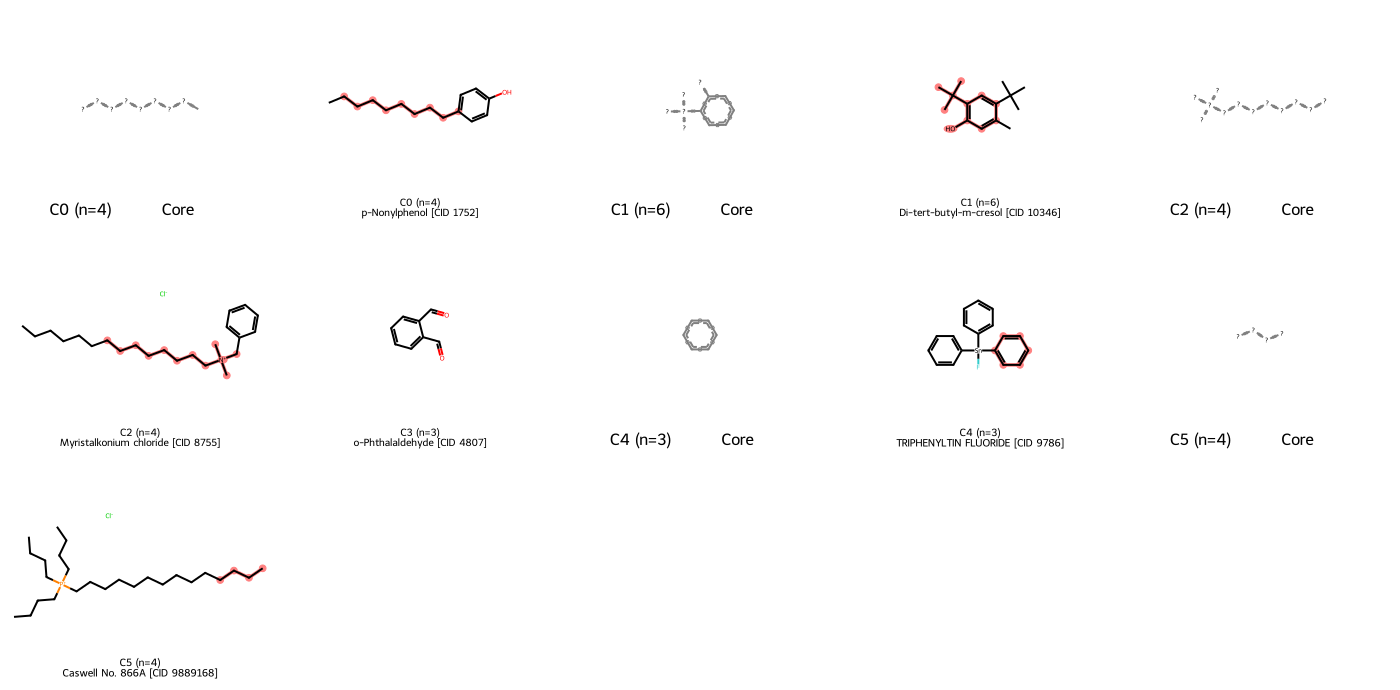

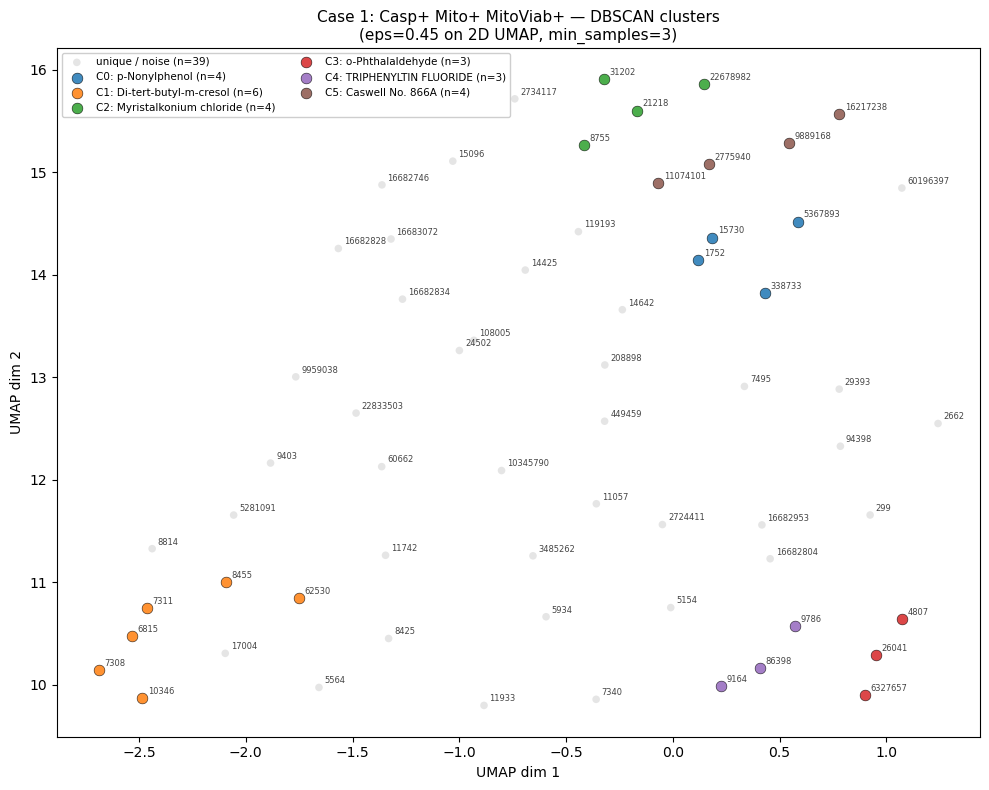

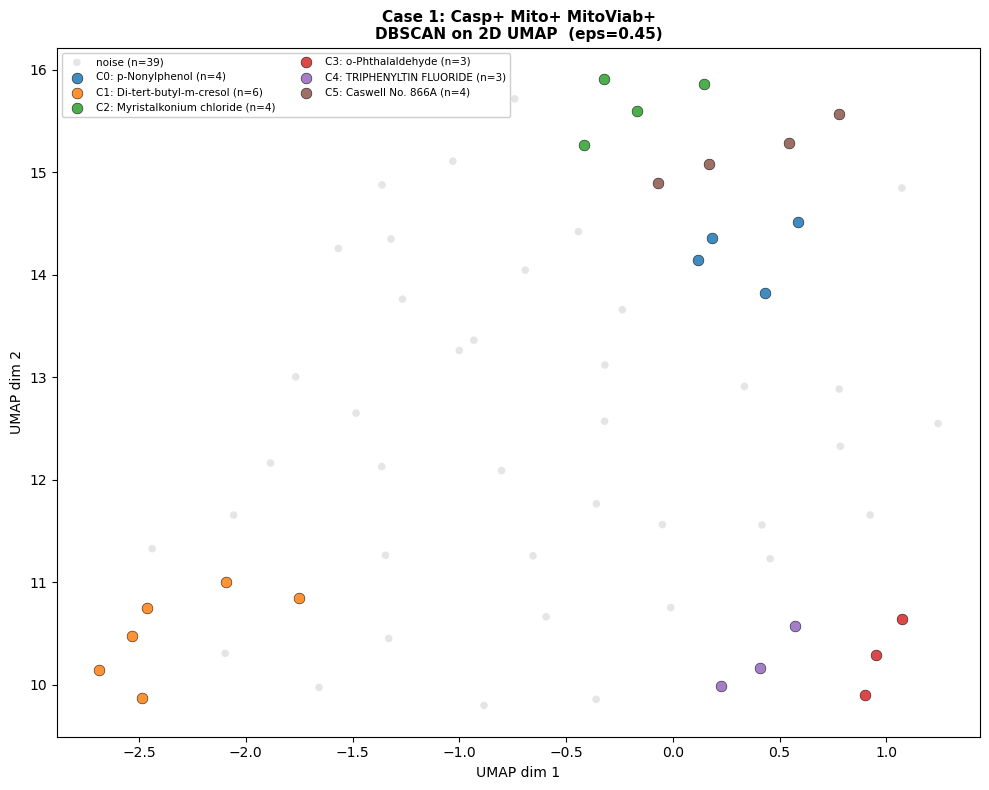

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_mito_comparisons/umap_dbscan_case1_caspase_active_mito_active_viability_active.png

  Case 2: Casp+ Mito+ MitoViab-
Unique CIDs: 43
Valid molecules: 43


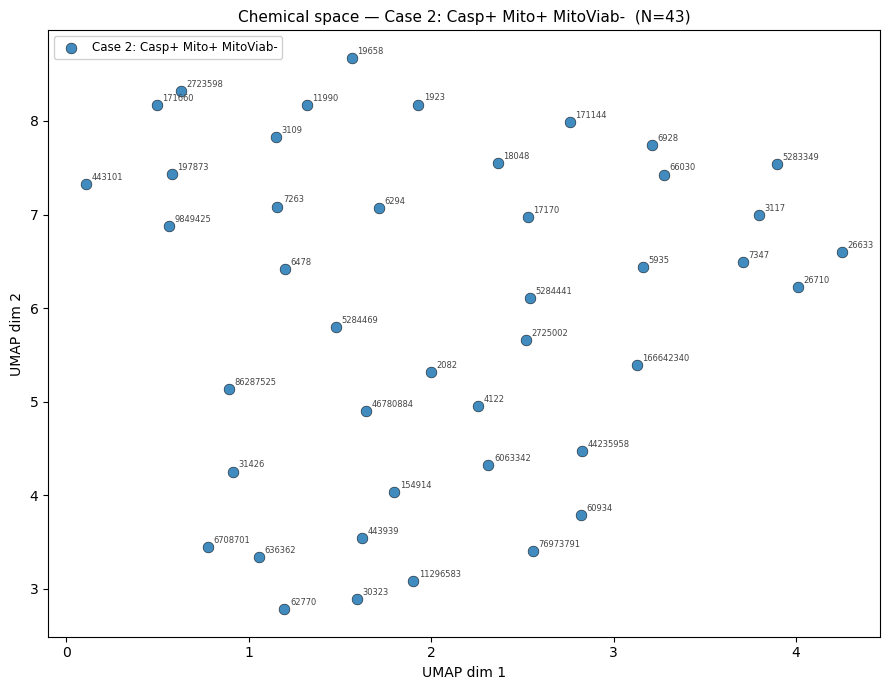

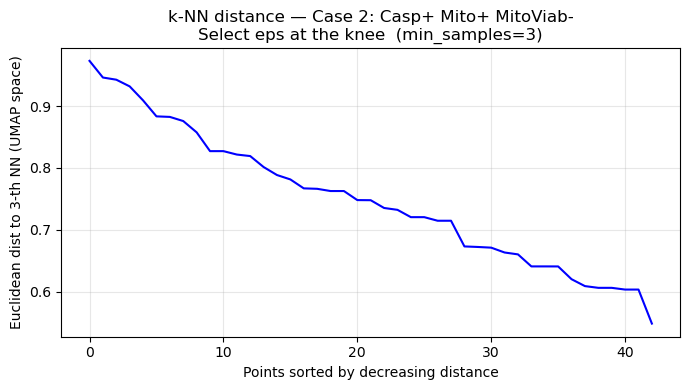

  Min=0.5486  Median=0.7479  Max=0.9730

DBSCAN (eps=0.45, min_samples=3)  →  2 clusters,  37 noise (86.0%)
           Count
Noise         37
Cluster 0      3
Cluster 1      3
Fetching PubChem names — Case 2: Casp+ Mito+ MitoViab-...
  Cluster  0 (n=   3)  Ferbam  [CID 26710]
  Cluster  1 (n=   3)  daunorubicin  [CID 30323]


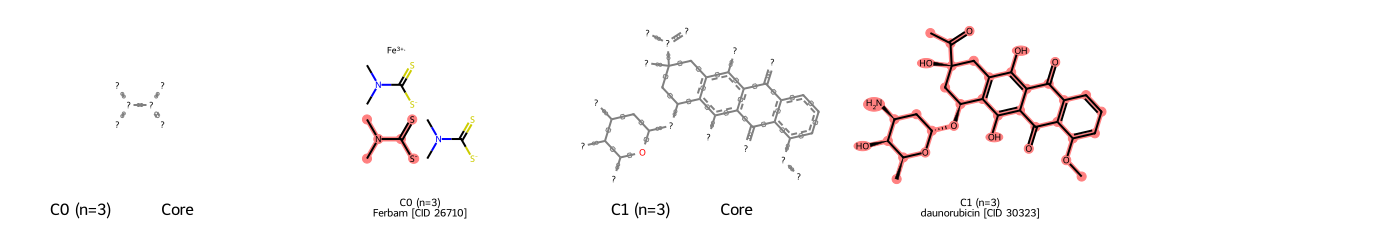

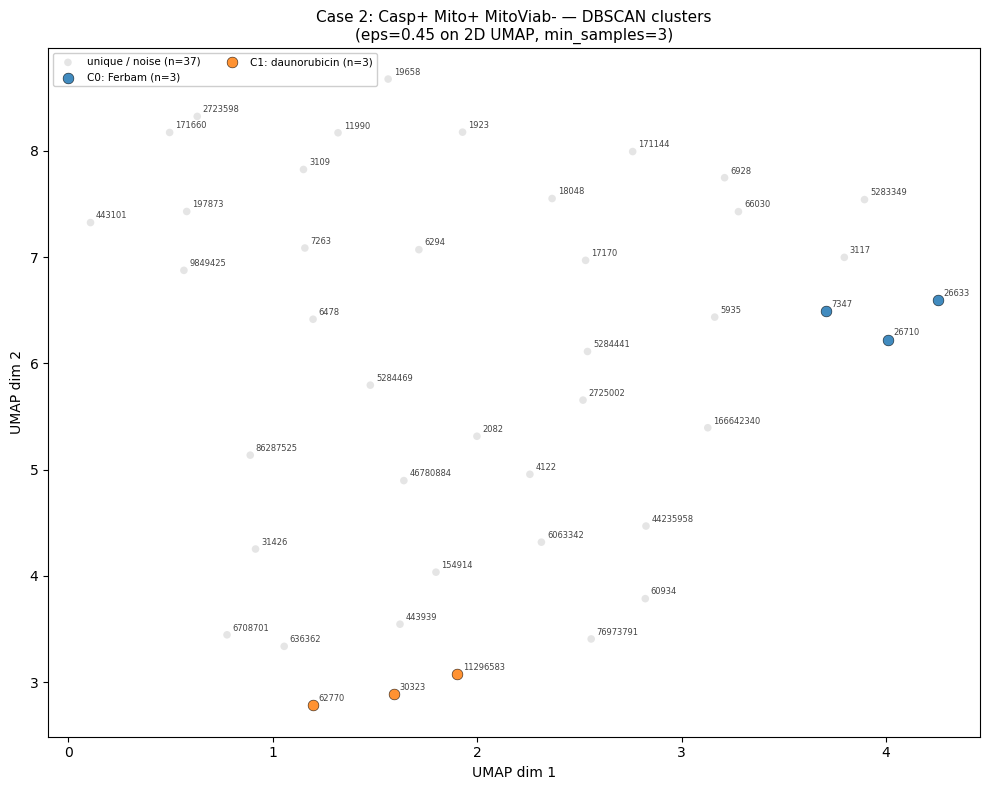

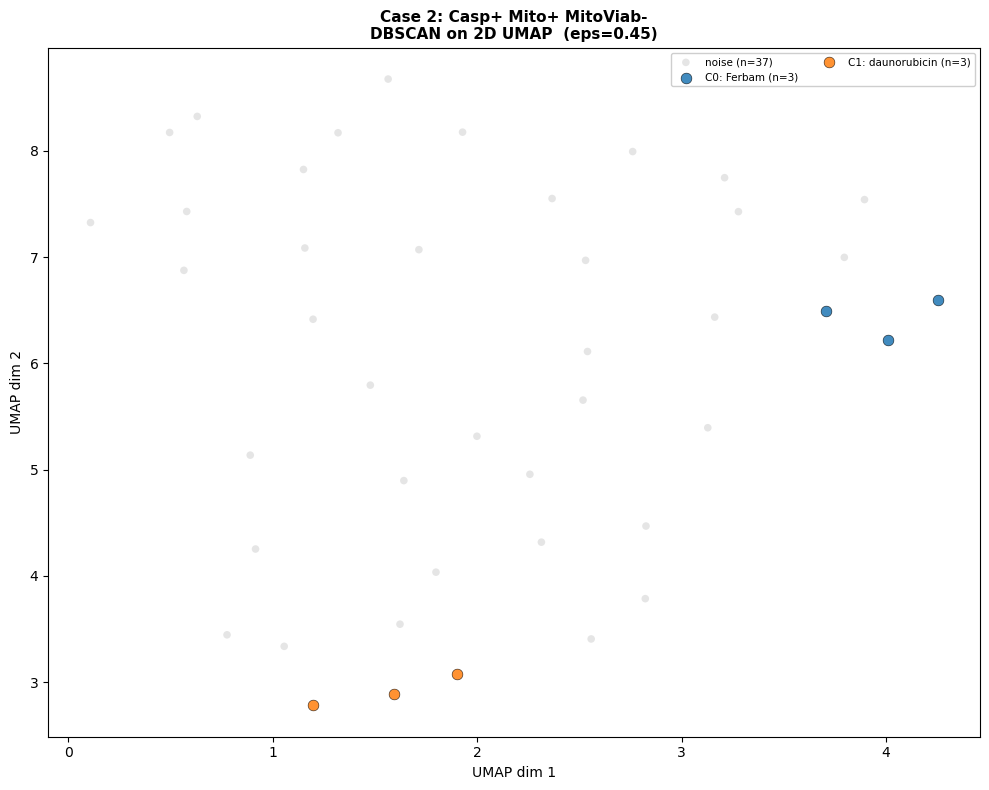

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_mito_comparisons/umap_dbscan_case2_caspase_active_mito_active_viability_inactive.png

  Case 3: Casp+ Mito- MitoViab+
Unique CIDs: 0
Valid molecules: 0
Too few molecules — skipping.

  Case 4: Casp+ Mito- MitoViab-
Unique CIDs: 17
Valid molecules: 17


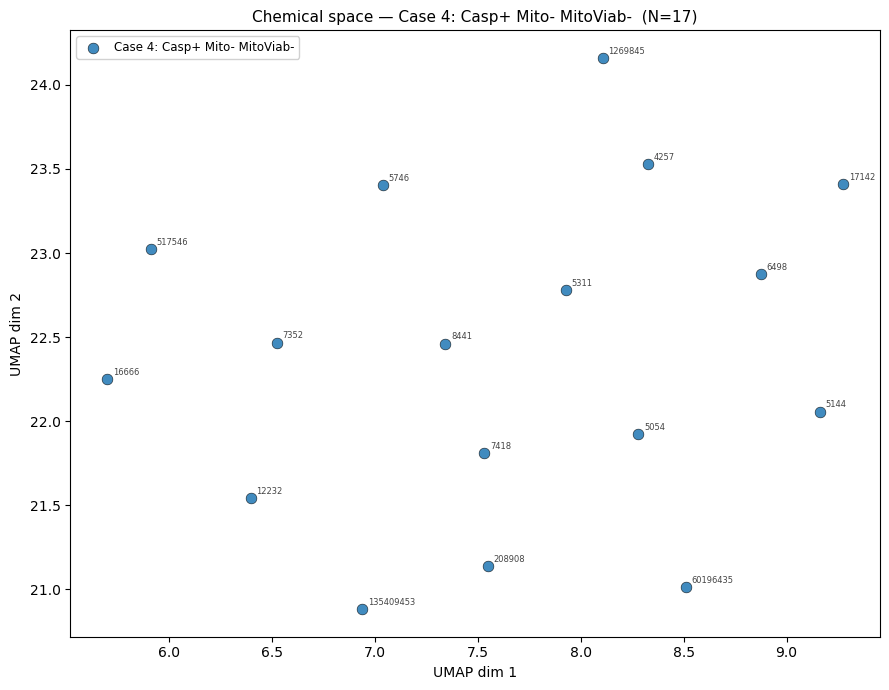

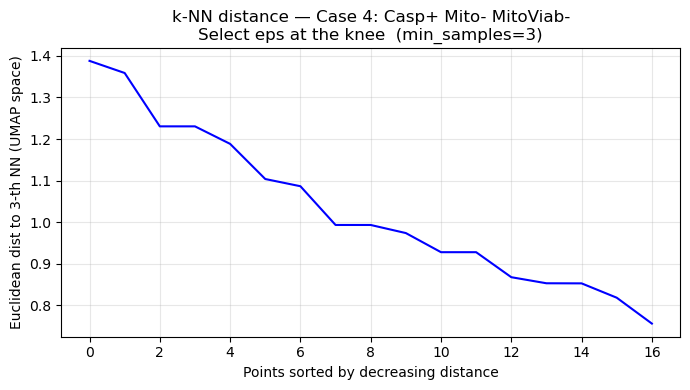

  Min=0.7559  Median=0.9932  Max=1.3880

DBSCAN (eps=0.45, min_samples=3)  →  0 clusters,  17 noise (100.0%)
       Count
Noise     17
Fetching PubChem names — Case 4: Casp+ Mito- MitoViab-...
  No clusters found — all compounds are structurally unique.


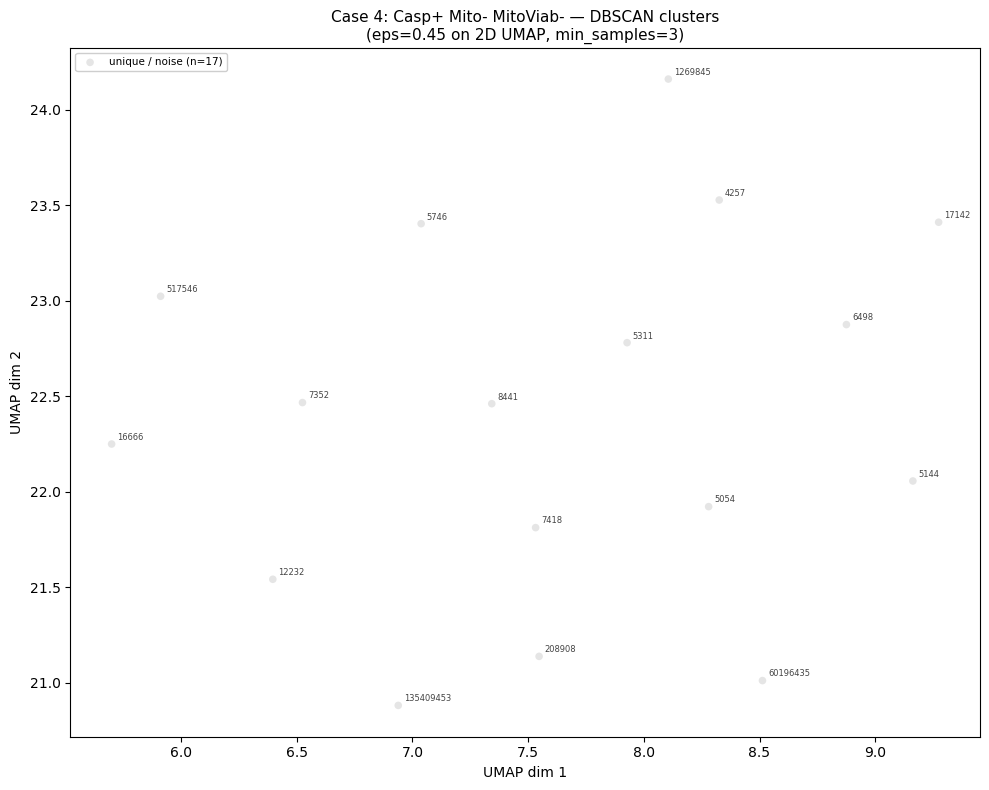

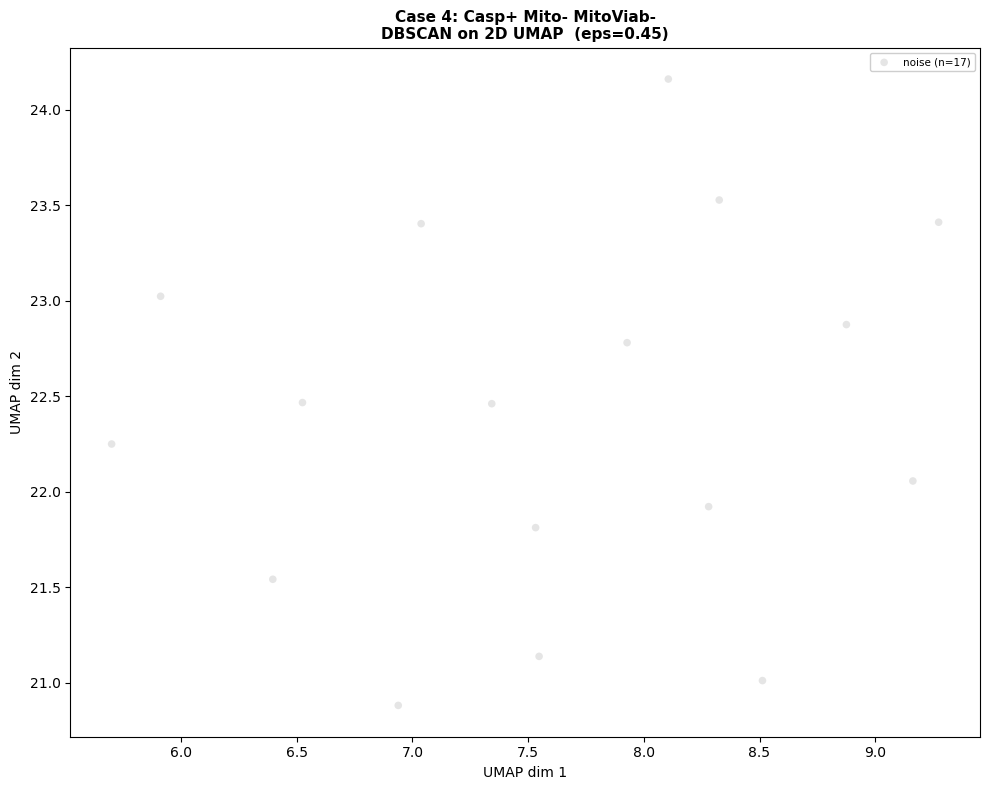

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_mito_comparisons/umap_dbscan_case4_caspase_active_mito_inactive_viability_inactive.png

  Case 5: Casp- Mito+ MitoViab+
Unique CIDs: 168
Valid molecules: 168


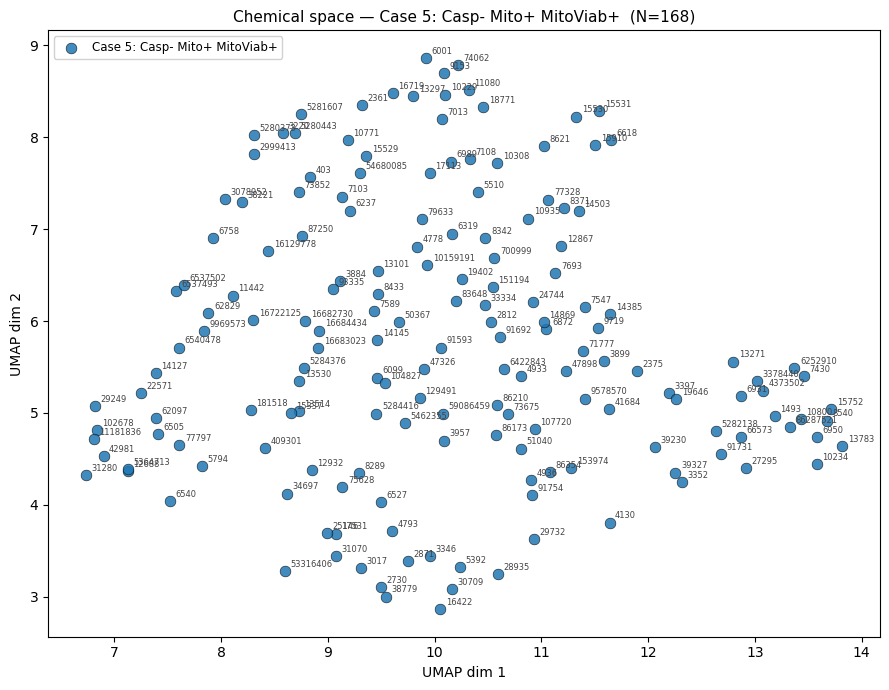

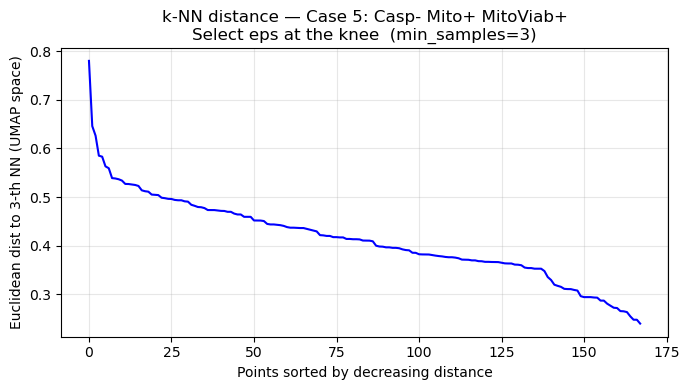

  Min=0.2402  Median=0.4108  Max=0.7798

DBSCAN (eps=0.45, min_samples=3)  →  12 clusters,  6 noise (3.6%)
            Count
Cluster 2      43
Cluster 5      25
Cluster 1      18
Cluster 3      18
Cluster 0      17
Cluster 7      13
Cluster 9       7
Noise           6
Cluster 4       5
Cluster 6       5
Cluster 8       5
Cluster 10      3
Cluster 11      3
Fetching PubChem names — Case 5: Casp- Mito+ MitoViab+...
  Cluster  0 (n=  17)  Phenanthren-9-ol  [CID 10229]
  Cluster  1 (n=  18)  Aldifen  [CID 1493]
  Cluster  2 (n=  43)  14869  [CID 14869]
  Cluster  3 (n=  18)  3346  [CID 3346]
  Cluster  4 (n=   5)  5280443  [CID 5280443]
  Cluster  5 (n=  25)  PHENYLMERCURIC LACTATE  [CID 16683023]
  Cluster  6 (n=   5)  Drometrizole  [CID 17113]
  Cluster  7 (n=  13)  Allethrins  [CID 11442]
  Cluster  8 (n=   5)  BROMOXYNIL  [CID 15531]
  Cluster  9 (n=   7)  RefChem:1069710  [CID 29249]
  Cluster 10 (n=   3)  39327  [CID 39327]
  Cluster 11 (n=   3)  Pelagol Grey  [CID 38221]


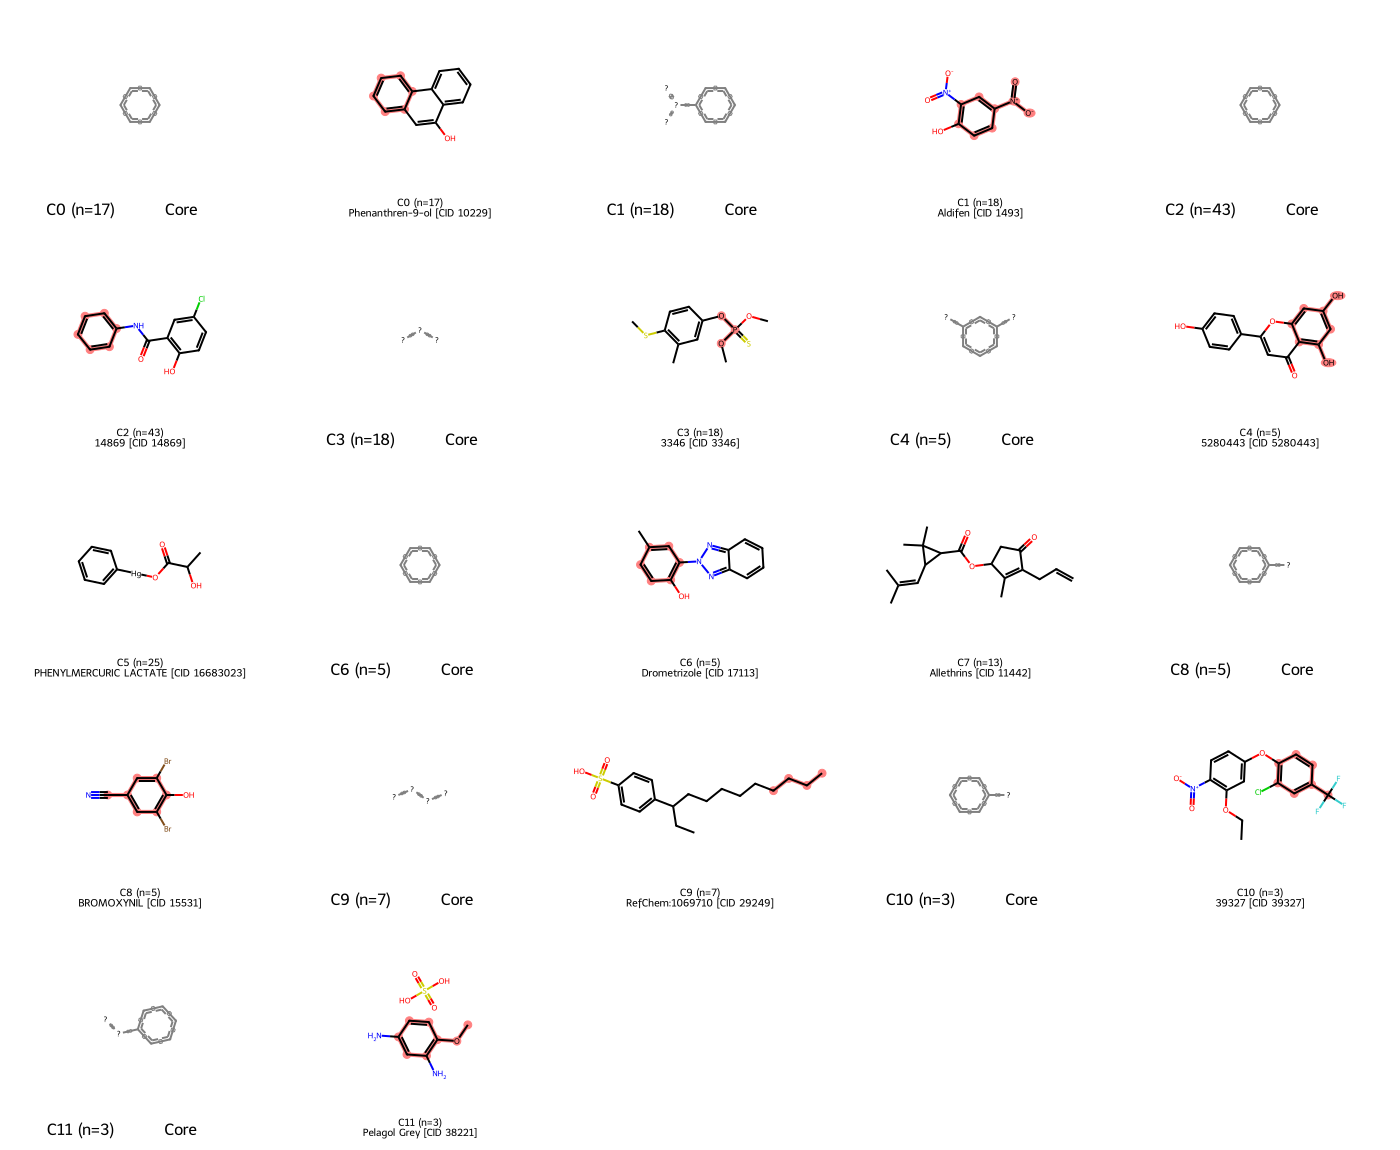

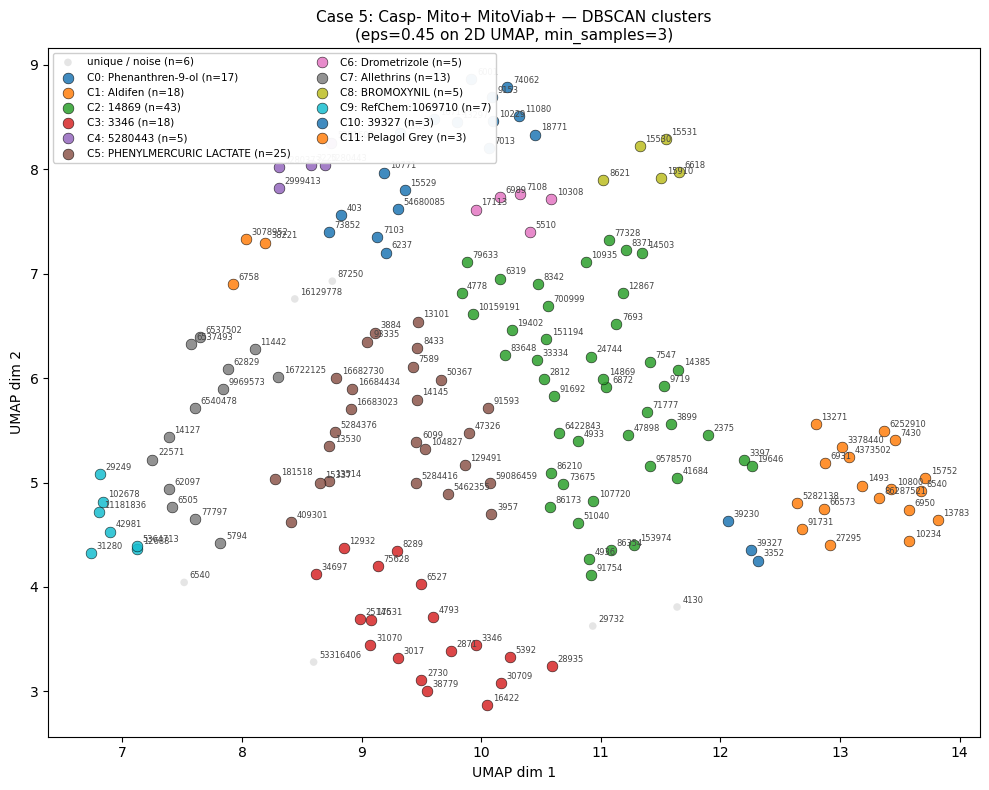

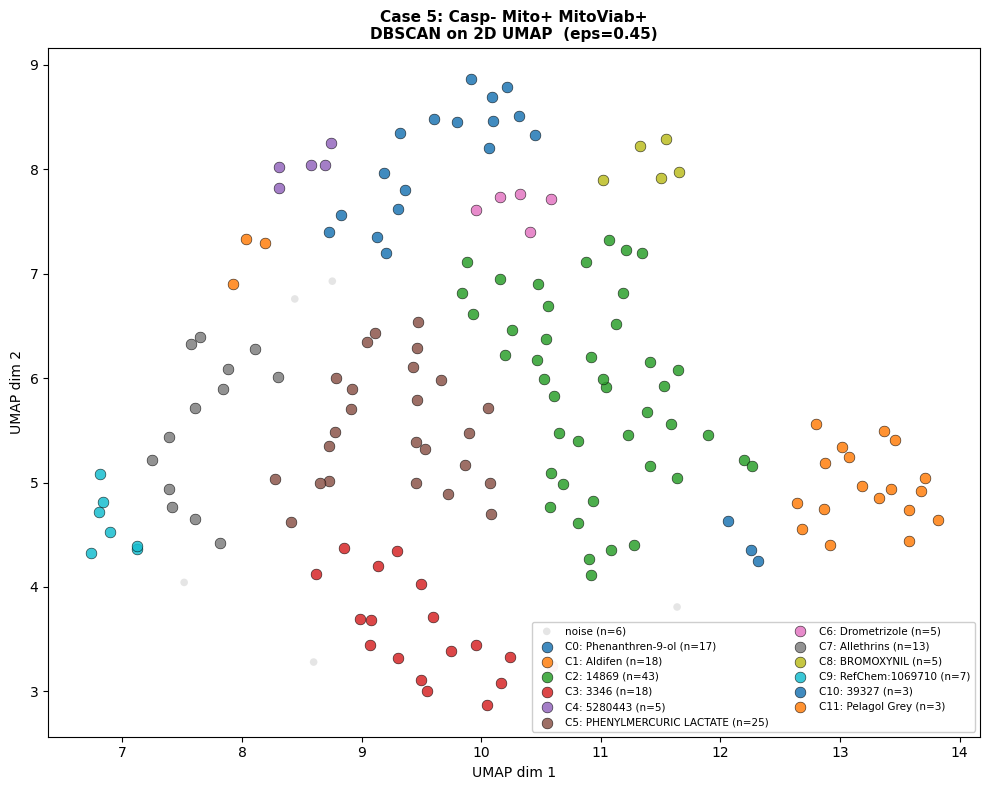

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_mito_comparisons/umap_dbscan_case5_caspase_inactive_mito_active_viability_active.png

  Case 6: Casp- Mito+ MitoViab-
Unique CIDs: 484
Valid molecules: 484


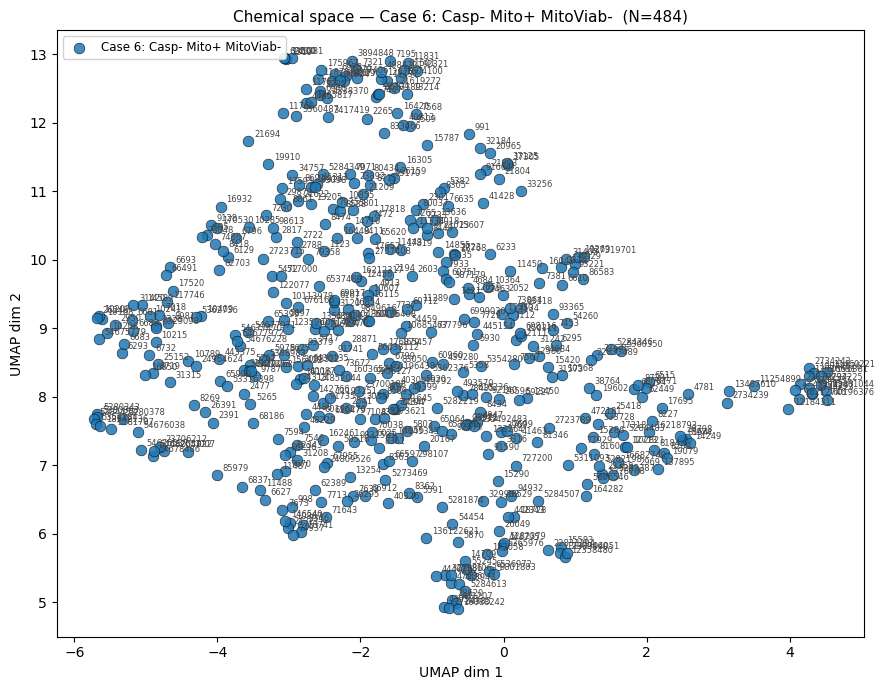

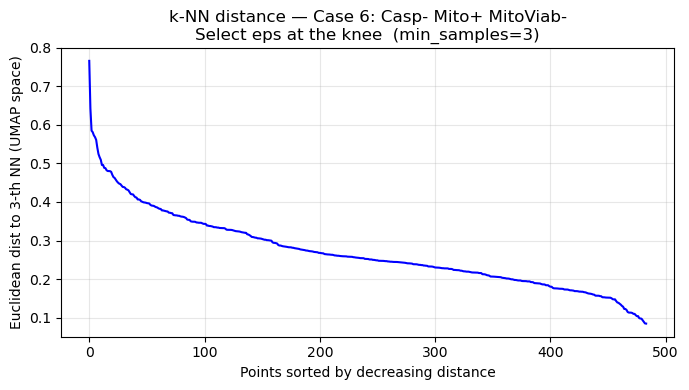

  Min=0.0845  Median=0.2520  Max=0.7660

DBSCAN (eps=0.45, min_samples=3)  →  9 clusters,  0 noise (0.0%)
           Count
Cluster 0    391
Cluster 2     39
Cluster 7     15
Cluster 5     14
Cluster 1     10
Cluster 6      5
Cluster 3      4
Cluster 4      3
Cluster 8      3
Fetching PubChem names — Case 6: Casp- Mito+ MitoViab-...
  Cluster  0 (n= 391)  m-Hydroxybenzophenone  [CID 83050]
  Cluster  1 (n=  10)  Chlorpyrifos oxon  [CID 21804]
  Cluster  2 (n=  39)  Benzenamine, 2,4-dinitro-  [CID 7321]
  Cluster  3 (n=   4)  benfluralin  [CID 2319]
  Cluster  4 (n=   3)  OXYPHENISATIN ACETATE  [CID 8269]
  Cluster  5 (n=  14)  warfarin  [CID 54678486]
  Cluster  6 (n=   5)  ENDRIN  [CID 12358480]
  Cluster  7 (n=  15)  DTXSID5047873  [CID 2734223]
  Cluster  8 (n=   3)  DTXSID2049345  [CID 13487610]


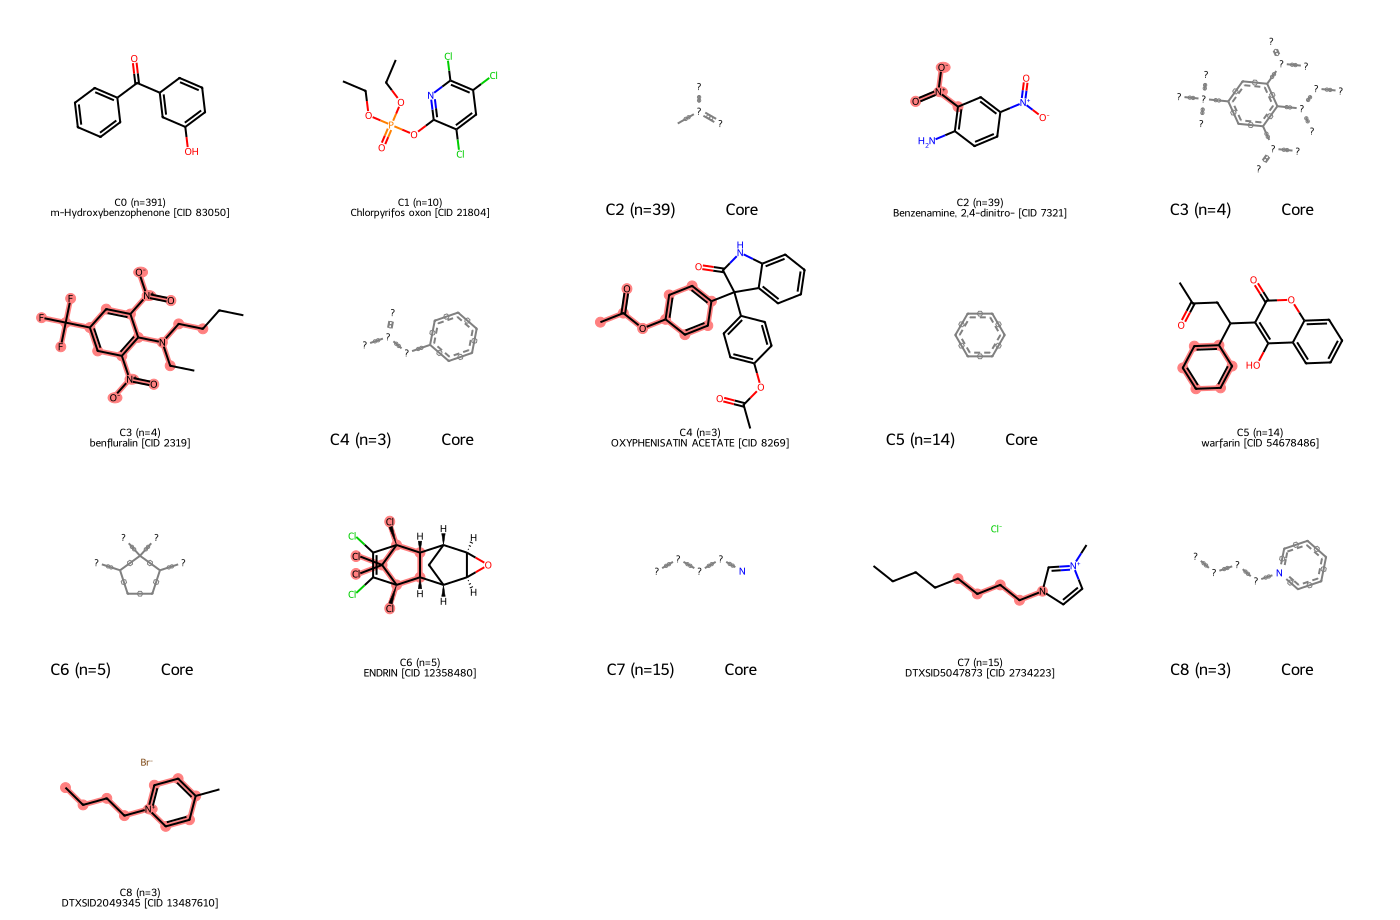

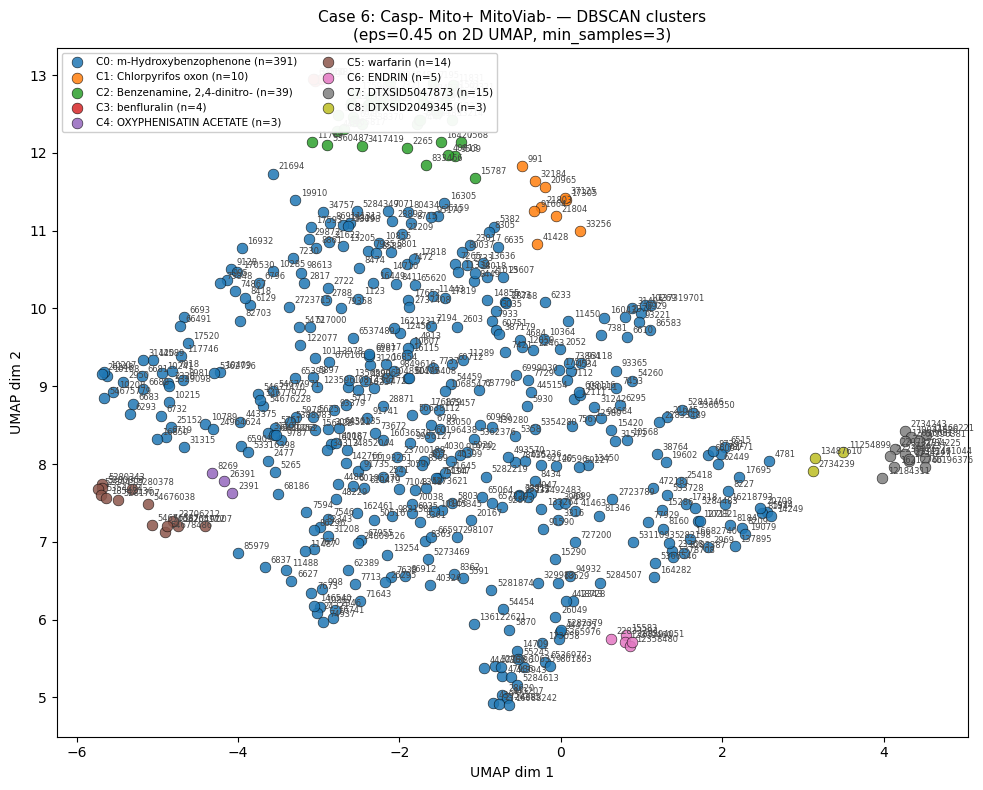

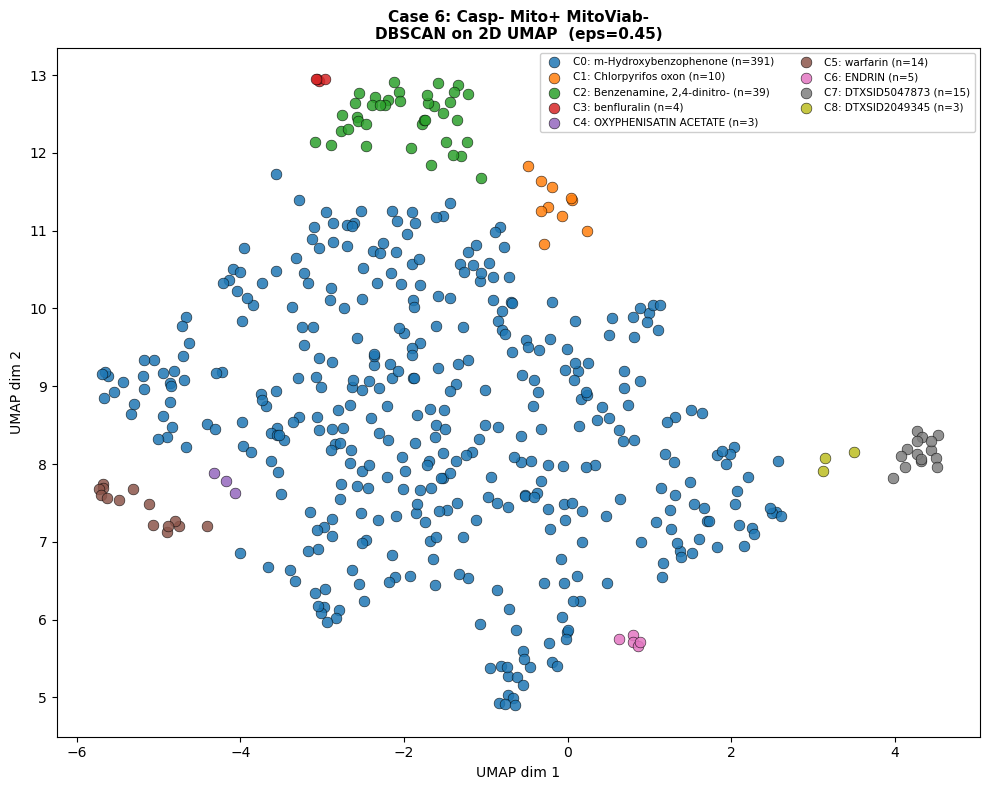

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_mito_comparisons/umap_dbscan_case6_caspase_inactive_mito_active_viability_inactive.png

  Case 7: Casp- Mito- MitoViab+
Unique CIDs: 0
Valid molecules: 0
Too few molecules — skipping.

  Case 8: Casp- Mito- MitoViab-
Unique CIDs: 2614


[16:03:26] WARNING: not removing hydrogen atom without neighbors


Valid molecules: 2614


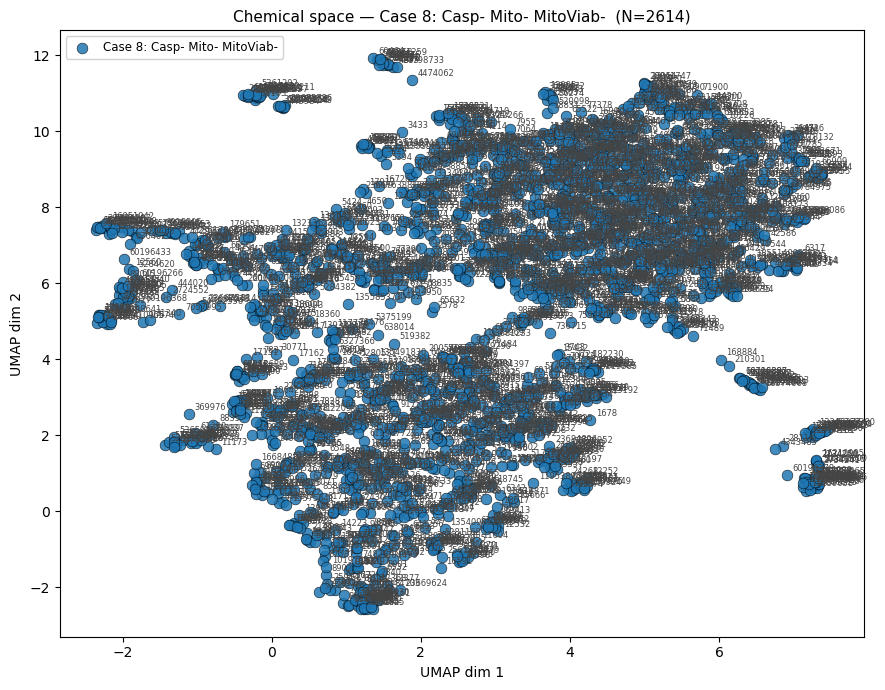

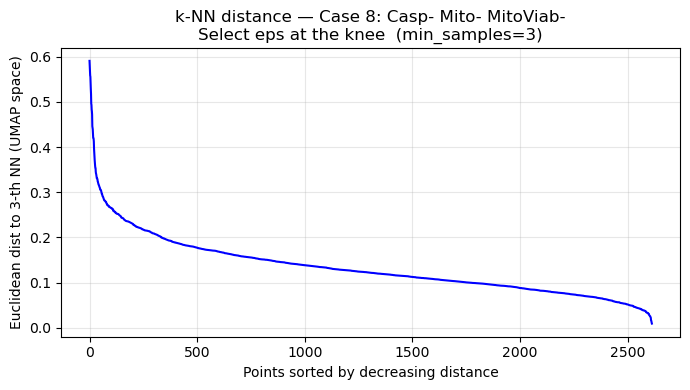

  Min=0.0094  Median=0.1217  Max=0.5908

DBSCAN (eps=0.45, min_samples=3)  →  6 clusters,  2 noise (0.1%)
           Count
Cluster 0   2497
Cluster 5     33
Cluster 2     26
Cluster 3     19
Cluster 4     19
Cluster 1     18
Noise          2
Fetching PubChem names — Case 8: Casp- Mito- MitoViab-...
  Cluster  0 (n=2497)  ETHYL BENZOATE  [CID 7165]
  Cluster  1 (n=  18)  Gatifloxacin  [CID 5379]
  Cluster  2 (n=  26)  cephalothin  [CID 6024]
  Cluster  3 (n=  19)  BPMBF4  [CID 2734180]
  Cluster  4 (n=  19)  DTXSID4049375  [CID 11009532]
  Cluster  5 (n=  33)  DTXSID7049342  [CID 11448496]


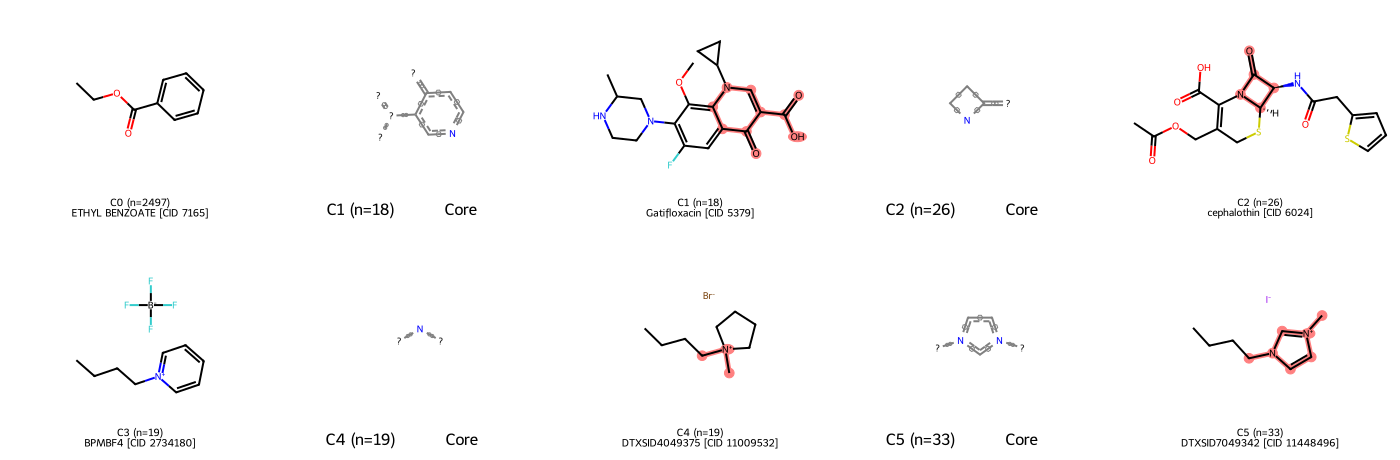

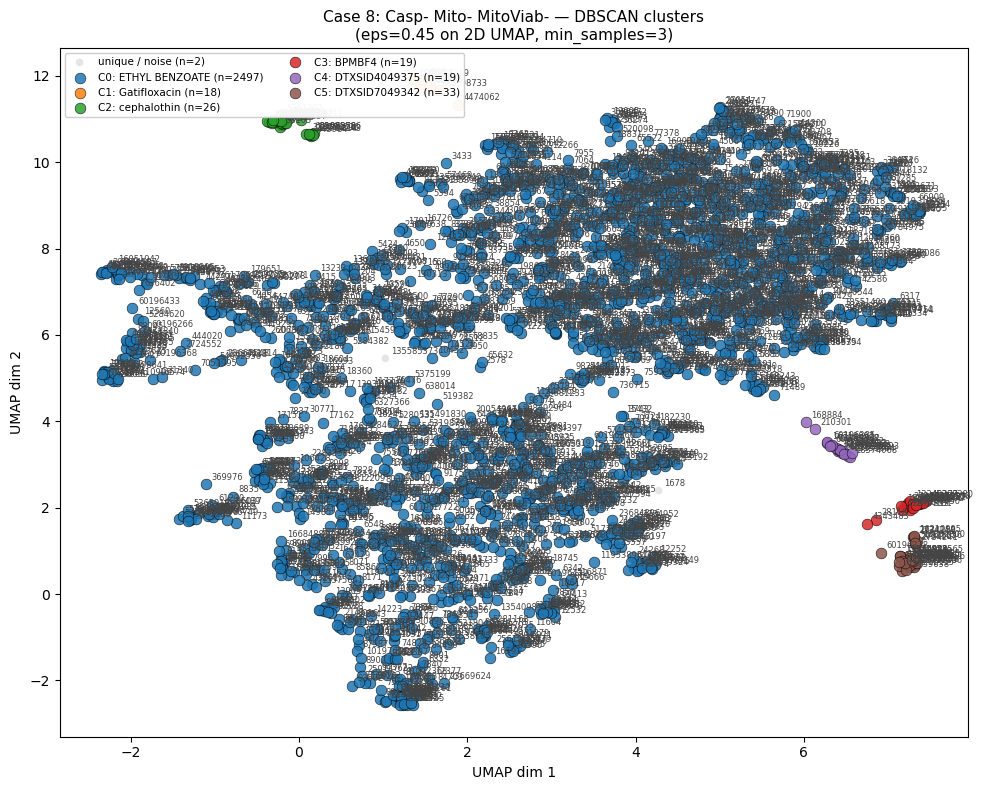

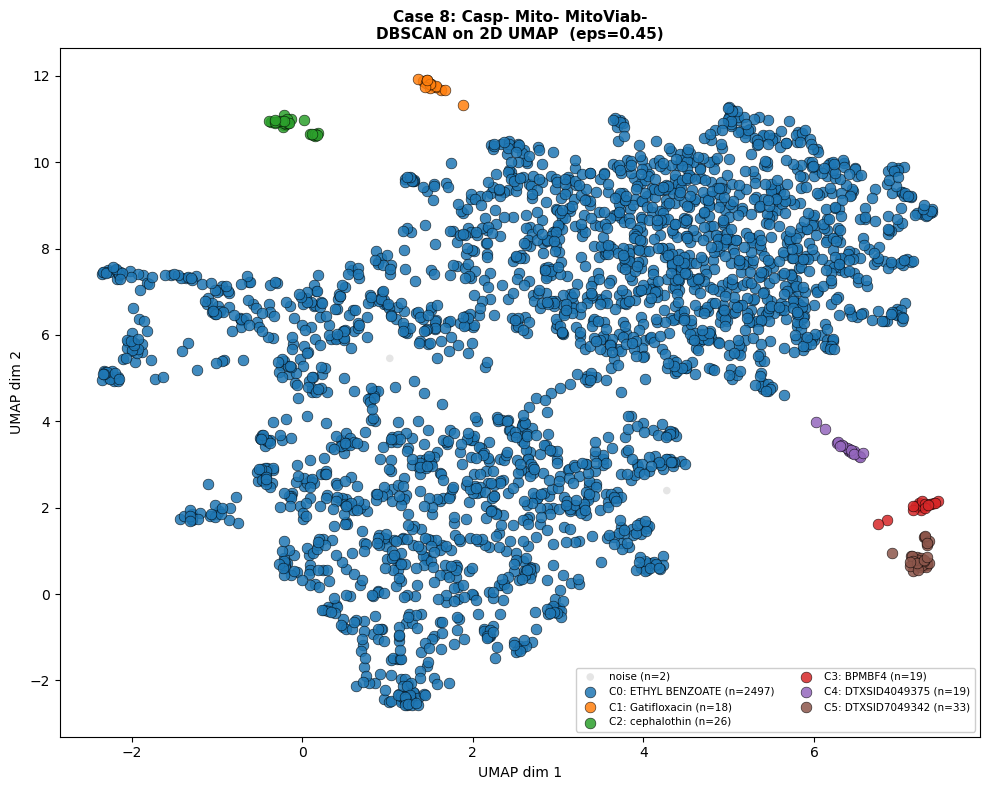

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_mito_comparisons/umap_dbscan_case8_caspase_inactive_mito_inactive_viability_inactive.png



In [4]:
# ── EPS for DBSCAN in 2D UMAP space (Euclidean) ──────────────────────────────
# 1. Run this cell → inspect the k-NN distance plot per dataset.
# 2. Find the 'knee' (where the curve bends sharply).
# 3. Set EPS to that y-value and re-run.
# Typical range in 2D UMAP space: 0.3–0.7  (much smaller than Jaccard on FPs)
EPS         = 0.45   # <-- adjust after inspecting the k-NN plots below
MIN_SAMPLES = 3      # minimum cluster size

for label, fname in DATASETS:
    print('=' * 65)
    print(f'  {label}')
    print('=' * 65)

    # ── Load ──────────────────────────────────────────────────────────
    df = pd.read_csv(
        RESULTS + fname,
        usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'],
        low_memory=False, encoding=ENCODING
    ).dropna(subset=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
    df['PUBCHEM_CID'] = df['PUBCHEM_CID'].astype(int)
    df = df.drop_duplicates(subset='PUBCHEM_CID').reset_index(drop=True)
    print(f'Unique CIDs: {len(df)}')

    # ── Parse molecules + fingerprints ────────────────────────────────
    df['mol'] = df['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
        lambda s: Chem.MolFromSmiles(str(s)) if pd.notna(s) else None)
    df = df[df['mol'].notna()].reset_index(drop=True)
    fps_rdkit, fp_matrix = to_fp_matrix(df['mol'].tolist())
    df['fp'] = fps_rdkit
    N = len(df)
    print(f'Valid molecules: {N}')

    if N < 10:
        print('Too few molecules — skipping.\n')
        continue

    # ── UMAP: Jaccard on fingerprints → 2D ────────────────────────────
    emb = plot_umap(
        fp_matrix,
        labels   = [label] * N,
        title    = f'Chemical space — {label}  (N={N})',
        annotate = df['PUBCHEM_CID'],
    )
    df['umap_x'], df['umap_y'] = emb[:, 0], emb[:, 1]

    # ── k-NN distance plot on 2D UMAP coords (Euclidean) ─────────────
    knn_eps_plot(emb, MIN_SAMPLES, f'k-NN distance — {label}')

    # ── DBSCAN on 2D UMAP (Euclidean) ────────────────────────────────
    db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(emb)
    df['cluster'] = db.labels_
    n_cl    = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
    n_noise = (db.labels_ == -1).sum()
    print(f'\nDBSCAN (eps={EPS}, min_samples={MIN_SAMPLES})'
          f'  →  {n_cl} clusters,  {n_noise} noise ({100*n_noise/N:.1f}%)')

    comp = df.groupby('cluster').size().rename('Count').to_frame()
    comp.index = ['Noise' if i == -1 else f'Cluster {i}' for i in comp.index]
    print(comp.sort_values('Count', ascending=False).to_string())

    cl_names = draw_cluster_reps(df, title=label)
    umap_by_cluster(df, cl_names,
                    title=f'{label} — DBSCAN clusters\n'
                          f'(eps={EPS} on 2D UMAP, min_samples={MIN_SAMPLES})')

    fig, ax = plt.subplots(figsize=(10, 8))
    cmap = plt.cm.tab10
    noise_df = df[df['cluster'] == -1]
    if len(noise_df):
        ax.scatter(noise_df['umap_x'], noise_df['umap_y'], c='#cccccc',
                   s=30, alpha=0.5, edgecolors='none',
                   label=f'noise (n={len(noise_df)})')
    for cl in sorted(c for c in df['cluster'].unique() if c != -1):
        sub  = df[df['cluster'] == cl]
        name = cl_names.get(cl, f'Cluster {cl}')
        ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
                   s=60, edgecolors='black', linewidths=0.4, alpha=0.85,
                   label=f'C{cl}: {name} (n={len(sub)})')
    ax.legend(fontsize=7.5, ncol=2, framealpha=0.95)
    ax.set_title(f'{label}\nDBSCAN on 2D UMAP  (eps={EPS})',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout()
    slug = fname.replace('.csv', '')
    out  = RESULTS + f'umap_dbscan_{slug}.png'
    plt.savefig(out, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved → {out}\n')
